# Fukushima data

> Load the Fukushima MIR spectra and soil properties as a `Spectra`, for the current sample selection

In [ ]:
#| default_exp data

In [ ]:
#| export
import os, re
from pathlib import Path
import numpy as np, pandas as pd
import ossl_fuku_transfer
from soilspecdata.readers import load_spa
from soilspecdata.types import Spectra

In [ ]:
from fastcore.test import *
import matplotlib.pyplot as plt

The Fukushima data is not public. The cells that read it are marked `#| fukudata`, and `nbdev-test` skips them unless you run `nbdev-test --flags fukudata`. The outputs on this page come from a local run.

## Data location

In [ ]:
#| export
def data_path()->Path: # Folder holding the data shared by the soilspec projects
    "The `SOILSPEC_DATA` folder if that variable is set, else `data/` in the soilspec workspace"
    p = os.environ.get('SOILSPEC_DATA')
    return Path(p) if p else Path(ossl_fuku_transfer.__file__).parents[2]/'data'

def fuku_path()->Path: # Folder holding the Fukushima data
    "The `fukushima` folder of `data_path()`"
    return data_path()/'fukushima'

The soilspec workspace keeps the data in `data/`, beside the project folders. Set `SOILSPEC_DATA` to use a folder elsewhere. The Fukushima data is in its `fukushima` folder:

In [ ]:
#| fukudata
assert fuku_path().is_dir()
sorted(o.name for o in fuku_path().iterdir())

['MIRS_rawData', 'reference']

## Soil properties

In [ ]:
#| export
def load_props()->pd.DataFrame: # One row per sample, indexed by sample ID
    "Soil properties of the Fukushima samples"
    df = pd.read_csv(fuku_path()/'MIRS_rawData'/'WetData_2013_2023.csv').dropna(subset=['ID'])
    return df.assign(ID=df.ID.astype(int).astype(str)).set_index('ID')

`load_props` reads the laboratory measurements in `WetData_2013_2023.csv`. Sample IDs are strings, as in `Spectra.sample_ids`. Soil property columns start with `soil_`, for example exchangeable potassium (`soil_ex_K2O`), CEC (`soil_CEC`) and carbon (`soil_C`):

In [ ]:
#| fukudata
props = load_props()
props.shape, [c for c in props.columns if c.startswith('soil_')]

((2003, 37),
 ['soil_harvest_date',
  'soil_water_soluble_K2O',
  'soil_available_K2O',
  'soil_ex_K2O',
  'soil_pH(H2O)',
  'soil_C',
  'soil_N',
  'soil_CN_ratio',
  'soil_CEC',
  'soil_MgO',
  'soil_CaO',
  'soil_P_absorption_coefficient'])

Exchangeable potassium, `soil_ex_K2O`, is in mg K₂O per 100 g of dry soil. OSSL gives Kex in cmolc/kg. 1 cmolc/kg of K is 391 mg K per kg, or 39.1 mg K per 100 g. As K₂O (94.2 g/mol, two K per molecule), that is 47.1 mg K₂O per 100 g:

In [ ]:
#| export
mg_k2o_per_cmolc = 47.1 # mg K₂O per 100 g of soil in 1 cmolc/kg of exchangeable K

In [ ]:
#| fukudata
kex = props['soil_ex_K2O'] / mg_k2o_per_cmolc
kex.describe().round(2).to_dict()

{'count': 1998.0,
 'mean': 0.74,
 'std': 0.48,
 'min': 0.06,
 '25%': 0.41,
 '50%': 0.63,
 '75%': 0.93,
 'max': 4.99}

## Sample selection

The selection is provisional. It can change after review with the Fukushima colleagues.

It starts from the 1,592 samples of the earlier Cs137 ratio study, listed in `reference/cs137_ratio_metadata.csv`. Results stay comparable with that study. 1,401 of them have Thermo OMNIC `.spa` files. The samples in `excluded` are left out while any of their scans is in doubt:

In [ ]:
#| export
excluded = { # Sample ID: reason for leaving the sample out
    **{i: 'scans by two operators disagree' for i in ('748', '989', '1165', '1986')},
    **{i: '`.spa` file differs from its absorbance CSV export' for i in ('1943', '2346', '2430', '2529', '2532')},
    '1531': 'unlettered `.spa` file beside replicates a-d',
    '177': 'duplicate `.spa` file for replicate b',
    '1984': 'earlier processed spectrum does not match the `.spa` files',
}

In [ ]:
#| export
def spa_files()->dict: # Sample ID: `.spa` files of its replicates
    "The `.spa` files of the Fukushima soil samples, by sample ID"
    res = {}
    for f in sorted((fuku_path()/'MIRS_rawData'/'Thermo'/'original').glob('FukushimaSoil_*/*')):
        m = re.match(r'^\d+', f.name)
        if m and f.suffix.lower() == '.spa': res.setdefault(m[0], []).append(f)
    return res

def sample_ids()->np.ndarray: # Sample IDs, in increasing order
    "IDs of the samples in the current selection"
    ref = set(pd.read_csv(fuku_path()/'reference'/'cs137_ratio_metadata.csv', usecols=['ID']).ID.astype(str))
    return np.array(sorted((ref & set(spa_files())) - set(excluded), key=int))

`sample_ids` applies the selection. Most samples have four replicates, `a` to `d`:

In [ ]:
#| fukudata
ids = sample_ids()
files = spa_files()
test_eq(len(ids), 1401 - len(excluded))
len(ids), pd.Series([len(files[i]) for i in ids]).value_counts().to_dict()

(1389, {4: 1382, 3: 5, 1: 1, 2: 1})

The earlier Cs137 ratio study split its samples into training and test sets. Its test set is the fixed Fukushima test set of this project. `cs137_split` keeps the samples of each set that are in the current selection:

In [ ]:
#| export
def cs137_split()->tuple: # (training IDs, test IDs), each in increasing order
    "Training and test sample IDs of the Cs137 ratio study, within the current selection"
    ids = sample_ids()
    test = pd.read_csv(fuku_path()/'reference'/'cs137_ratio_test.csv', usecols=['ID']).ID.astype(str)
    is_test = np.isin(ids, test)
    return ids[~is_test], ids[is_test]

In [ ]:
#| fukudata
train_ids, test_ids = cs137_split()
test_eq(len(train_ids) + len(test_ids), len(ids))
len(train_ids), len(test_ids)

(1048, 341)

Each folder of `.spa` files is one measurement batch. `sample_batches` numbers the batches in the sorted order of their folders:

In [ ]:
#| export
def sample_batches(
    ids, # Sample IDs
)->np.ndarray: # Batch label of each sample, such as 'batch 1'
    "The measurement batch of each sample"
    files = spa_files()
    dirs = sorted({fs[0].parent.name for fs in files.values()})
    return np.array([f'batch {dirs.index(files[i][0].parent.name) + 1}' for i in ids])

In [ ]:
#| fukudata
pd.Series(sample_batches(ids)).value_counts().to_dict()

{'batch 2': 854, 'batch 1': 535}

## Loading

In [ ]:
#| export
shared_wns = np.arange(650, 3999, 2) # Wavenumbers that OSSL and every Fukushima batch cover, in cm⁻¹

def load_fuku(
    wns=shared_wns, # Wavenumbers to interpolate onto, in cm⁻¹, in increasing order
    ids=None, # Sample IDs to load; defaults to `sample_ids()`
)->Spectra: # One spectrum per sample, with the soil properties in `source`
    "Load the Fukushima spectra, averaging the replicates of each sample"
    files = spa_files()
    ids = sample_ids() if ids is None else ids
    res = load_spa([f for i in ids for f in files[i]], wns)
    res.source = load_props()
    return res

`load_fuku` interpolates each `.spa` file onto `shared_wns`, 2 cm⁻¹ from 650 to 3998 cm⁻¹, then averages the replicates of each sample. The rows follow `sample_ids()`:

In [ ]:
#| fukudata
fuku = load_fuku()
test_eq(fuku.spectra.shape, (len(ids), len(shared_wns)))
test_eq(fuku.sample_ids, ids)
fuku.spectra.shape, fuku.measurement_type

((1389, 1675), 'abs')

The CO₂ band, around 2300–2400 cm⁻¹, is still in the spectra:

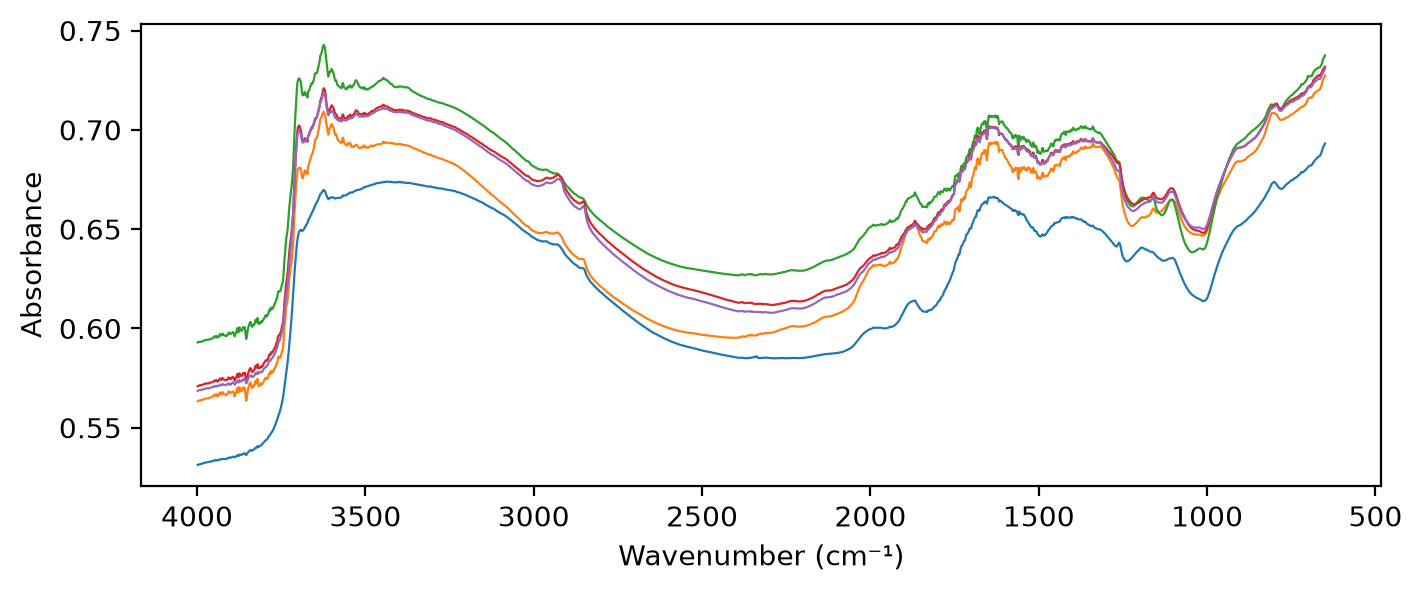

In [ ]:
#| fukudata
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(fuku.wavenumbers, fuku.spectra[:5].T, lw=0.8)
ax.invert_xaxis()
ax.set_xlabel('Wavenumber (cm⁻¹)'); ax.set_ylabel('Absorbance');

`Spectra.xy` returns the spectra and targets of the samples that have both:

In [ ]:
#| fukudata
X, y, xy_ids = fuku.xy('soil_ex_K2O')
X.shape, y.shape

((1388, 1675), (1388, 1))